# Certamen 1 · Ensambles, costo de clasificación y umbral óptimo
## CardioInsight — Detección de enfermedad cardiovascular

**Grupo 14 · Joaquín Rivas · Matías Ortega**

**Objetivo:** comparar cinco modelos en dos etapas (SMOTE y pesos), elegir el mejor por F1 de validación cruzada y traducir sus errores a dinero mediante un umbral de decisión.

Este notebook sigue la estructura y los nombres utilizados en las guías del profesor: `crear_preprocesamiento`, `crear_pipeline`, `StratifiedKFold`, búsqueda con CV y `TunedThresholdClassifierCV`.

**VS Code (macOS):** abre la carpeta `certamen 1`, selecciona arriba a la derecha el kernel **Python 3.13** de `certamen 1/.venv/bin/python` y luego ejecuta **Restart Kernel and Run All Cells**. Si no aparece, crea `.venv` con las instrucciones de `README.md` y vuelve a seleccionar el kernel. No uses el Python 3.14 global: allí falta `imblearn`.

## 1. Problema de negocio y base de datos

Una institución de salud debe priorizar a qué personas derivar a una evaluación cardiológica.

| Error | Interpretación | Valor usado |
|---|---|---:|
| FP | Derivación innecesaria: consulta cardiológica, ECG y ecocardiograma | CLP 100.000 |
| FN | Caso no detectado: retraso diagnóstico y posibles complicaciones | CLP 1.000.000 |

El FP se aproxima con el Arancel MLE FONASA 2025. El FN es un **supuesto gerencial conservador de 10×**, no una tarifa: un estudio chileno reportó CLP 423.300 por día UCI cardiovascular en valores de 2011. La razón FN/FP se somete a sensibilidad entre 2× y 50×.

- Dataset procesado: https://www.kaggle.com/datasets/alexteboul/heart-disease-health-indicators-dataset
- Fuente primaria: https://www.cdc.gov/brfss/annual_data/annual_2015.html
- Target: `HeartDiseaseorAttack`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
ROOT = next(
    (carpeta for carpeta in (Path.cwd(), Path.cwd() / "certamen 1")
     if (carpeta / "entrenar_modelo.py").is_file()
     and (carpeta / "heart_disease_health_indicators_BRFSS2015.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Abre 'certamen 1' en VS Code, o abre su carpeta padre: "
        "faltan entrenar_modelo.py y el CSV del certamen."
    )
sys.path.insert(0, str(ROOT))


from entrenar_modelo import (
    COLUMNAS_CATEGORICAS,
    COLUMNAS_NUMERICAS,
    SEED,
    TARGET,
    crear_modelo,
    crear_pipeline,
    obtener_grilla,
)

plt.style.use("ggplot")
ROOT = ROOT.resolve()
CSV = ROOT / "heart_disease_health_indicators_BRFSS2015.csv"
SALIDA = ROOT / "resultados"
C_FP, C_FN = 100_000, 1_000_000
print("Carpeta:", ROOT)

Carpeta: /Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1


### 1.1 Carga, requisitos y exploración breve

El archivo de Kaggle no contiene identificador de persona. Por eso las filas con respuestas idénticas se **conservan**: igualdad en 21 respuestas discretizadas no demuestra que sea la misma persona. Eliminar perfiles repetidos daría peso uno a cada combinación —no a cada encuestado— y sesgaría la muestra hacia perfiles infrecuentes.

In [2]:
df = pd.read_csv(CSV)
n_repetidas = int(df.duplicated().sum())
resumen_base = pd.Series({
    "Registros": len(df),
    "Predictoras": df.shape[1] - 1,
    "Nulos": int(df.isna().sum().sum()),
    "Filas idénticas conservadas": n_repetidas,
    "Proporción clase 1": df[TARGET].mean(),
    "Target binario": set(df[TARGET].unique()) == {0.0, 1.0},
})
display(resumen_base.to_frame("Valor"))

repetidas = df.duplicated(keep="first")
df_sin_repetidas = df.drop_duplicates()
print("Exceso de filas idénticas:", f"{repetidas.sum():,}")
print("Positivos que se eliminarían:", int(df.loc[repetidas, TARGET].sum()))
print("Negativos que se eliminarían:", int((1 - df.loc[repetidas, TARGET]).sum()))
print("Prevalencia original:", f"{df[TARGET].mean():.2%}")
print("Prevalencia con drop_duplicates:", f"{df_sin_repetidas[TARGET].mean():.2%}")

,Valor
Registros,253680
Predictoras,21
Nulos,0
Filas idénticas conservadas,23899
Proporción clase 1,0.094186
Target binario,True


Exceso de filas idénticas: 23,899
Positivos que se eliminarían: 176
Negativos que se eliminarían: 23723
Prevalencia original: 9.42%
Prevalencia con drop_duplicates: 10.32%


,Tipo,Nulos,Únicos,Mínimo,Máximo
HeartDiseaseorAttack,float64,0,2,0.0,1.0
HighBP,float64,0,2,0.0,1.0
HighChol,float64,0,2,0.0,1.0
CholCheck,float64,0,2,0.0,1.0
BMI,float64,0,84,12.0,98.0
Smoker,float64,0,2,0.0,1.0
Stroke,float64,0,2,0.0,1.0
Diabetes,float64,0,3,0.0,2.0
PhysActivity,float64,0,2,0.0,1.0
Fruits,float64,0,2,0.0,1.0


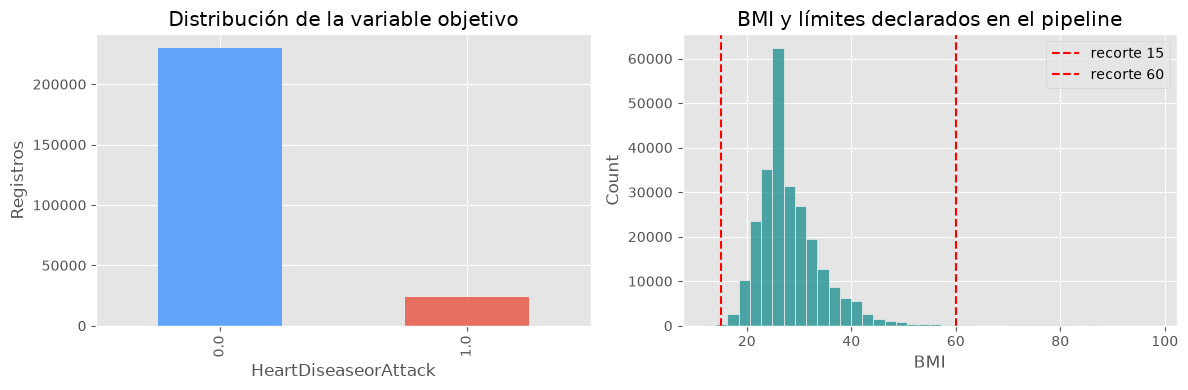

In [3]:
eda = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Nulos": df.isna().sum(),
    "Únicos": df.nunique(),
    "Mínimo": df.min(numeric_only=True),
    "Máximo": df.max(numeric_only=True),
})
display(eda)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color=["#60A5FA", "#E76F61"])
ax[0].set_title("Distribución de la variable objetivo")
ax[0].set_xlabel("HeartDiseaseorAttack")
ax[0].set_ylabel("Registros")
sns.histplot(df["BMI"], bins=40, ax=ax[1], color="#168C8C")
ax[1].axvline(15, ls="--", color="red", label="recorte 15")
ax[1].axvline(60, ls="--", color="red", label="recorte 60")
ax[1].set_title("BMI y límites declarados en el pipeline")
ax[1].legend()
plt.tight_layout()
plt.show()

## 2. Exploración, partición y pipeline

La partición se realiza antes de ajustar cualquier transformación. El pipeline aplica:

1. recorte de BMI dentro de `ColumnTransformer`;
2. `SMOTENC` solo en la Etapa A, porque hay variables binarias/ordinales;
3. escalamiento de BMI, salud mental y salud física;
4. modelo.

`SMOTENC` es la variante presentada en la plantilla de Netflix para impedir categorías sintéticas fraccionarias. Todo queda dentro del pipeline de `imblearn`, de modo que el balanceo ocurre solamente en el train de cada fold.

In [4]:
X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", len(y_train), "positivos:", f"{y_train.mean():.2%}")
print("Test :", len(y_test), "positivos:", f"{y_test.mean():.2%}")
print("Numéricas:", COLUMNAS_NUMERICAS)
print("Categóricas:", COLUMNAS_CATEGORICAS)

Train: 202944 positivos: 9.42%
Test : 50736 positivos: 9.42%
Numéricas: ['BMI', 'MentHlth', 'PhysHlth']
Categóricas: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [5]:
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()
pipe_ejemplo = crear_pipeline(
    crear_modelo("Árbol de decisión", "smote", neg_pos), usar_smote=True
)
display(pipe_ejemplo)

,steps,"[('limpieza', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bmi', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights tr

### 2.1 Ejecución reproducible del entrenamiento

`entrenar_modelo.py` contiene el flujo canónico completo. Para evitar recalcular durante cada apertura, el notebook reutiliza los artefactos finales cuando ya existen. Cambie `EJECUTAR_ENTRENAMIENTO` a `True` para regenerarlos con el mismo comando usado en la entrega.

In [6]:
EJECUTAR_ENTRENAMIENTO = False
comando = [
    sys.executable, str(ROOT / "entrenar_modelo.py"),
    "--csv", str(CSV),
    "--n-sub", "30000",
    "--n-iter", "10",
    "--cv-folds", "3",
    "--salida", str(SALIDA),
]
if EJECUTAR_ENTRENAMIENTO:
    subprocess.run(comando, check=True)
else:
    requeridos = ["comparacion.csv", "tabla_cv.csv", "estrategias.csv", "sensibilidad.csv", "resumen.json"]
    faltantes = [nombre for nombre in requeridos if not (SALIDA / nombre).exists()]
    if faltantes:
        raise FileNotFoundError(f"Faltan resultados: {faltantes}. Active EJECUTAR_ENTRENAMIENTO.")
    print("Se reutilizan resultados finales ya generados con:")
    print(" ".join(comando))

Se reutilizan resultados finales ya generados con:
/Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1/.venv/bin/python /Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1/entrenar_modelo.py --csv /Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1/heart_disease_health_indicators_BRFSS2015.csv --n-sub 30000 --n-iter 10 --cv-folds 3 --salida /Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1/resultados


In [7]:
comparacion = pd.read_csv(SALIDA / "comparacion.csv")
tabla_cv = pd.read_csv(SALIDA / "tabla_cv.csv")
estrategias = pd.read_csv(SALIDA / "estrategias.csv")
sensibilidad = pd.read_csv(SALIDA / "sensibilidad.csv")
datos_dashboard = pd.read_csv(SALIDA / "datos_dashboard.csv")
importancias = pd.read_csv(SALIDA / "importancias.csv")
resumen = json.loads((SALIDA / "resumen.json").read_text(encoding="utf-8"))

## 3. Etapa A — cinco modelos con SMOTE

Cada búsqueda usa F1 de la clase 1, `StratifiedKFold`, semilla fija y una submuestra estratificada de 30.000 filas. El ganador de cada búsqueda se reentrena con todo el train.

In [8]:
etapa_a = comparacion.query("Etapa == 'A: SMOTE'").sort_values("F1_cv", ascending=False)
display(etapa_a.round(3))
print("Ejemplo de grilla AdaBoost A:", obtener_grilla("AdaBoost", "smote"))

,Nombre,Modelo,Etapa,F1_cv,Desv_cv,F1_train,F1_test,Recall_test,Precision_test,AUC_test,PR_AUC_test,Tiempo_busqueda_s,Hiperparametros,Brecha
2,AdaBoost | A: SMOTE,AdaBoost,A: SMOTE,0.384,0.004,0.397,0.393,0.526,0.314,0.834,0.335,11.743,"{""n_estimators"": 400, ""learning_rate"": 1.0, ""e...",0.004
3,XGBoost | A: SMOTE,XGBoost,A: SMOTE,0.381,0.007,0.392,0.396,0.661,0.282,0.839,0.353,4.065,"{""n_estimators"": 200, ""max_depth"": 3, ""learnin...",-0.004
1,Random Forest | A: SMOTE,Random Forest,A: SMOTE,0.374,0.001,0.385,0.372,0.748,0.247,0.839,0.349,18.893,"{""n_estimators"": 400, ""max_features"": ""sqrt"", ...",0.013
4,LightGBM | A: SMOTE,LightGBM,A: SMOTE,0.368,0.011,0.388,0.390,0.462,0.337,0.833,0.342,4.297,"{""num_leaves"": 15, ""n_estimators"": 200, ""learn...",-0.002
0,Árbol de decisión | A: SMOTE,Árbol de decisión,A: SMOTE,0.347,0.008,0.356,0.358,0.751,0.235,0.824,0.301,5.295,"{""min_samples_leaf"": 10, ""max_depth"": 7}",-0.001


Ejemplo de grilla AdaBoost A: {'modelo__n_estimators': [100, 200, 300, 400], 'modelo__learning_rate': [0.1, 0.5, 1.0], 'modelo__estimator__max_depth': [1, 2, 3]}


## 4. Etapa B — cinco modelos con pesos

No se usa SMOTE. Árbol y Random Forest usan `class_weight='balanced'`; XGBoost usa `scale_pos_weight`; LightGBM usa `class_weight='balanced'`; AdaBoost usa un stump ponderado (`max_depth=1`).

In [9]:
etapa_b = comparacion.query("Etapa == 'B: Pesos'").sort_values("F1_cv", ascending=False)
display(etapa_b.round(3))
print("Grilla AdaBoost B (profundidad fija en 1):", obtener_grilla("AdaBoost", "pesos"))

,Nombre,Modelo,Etapa,F1_cv,Desv_cv,F1_train,F1_test,Recall_test,Precision_test,AUC_test,PR_AUC_test,Tiempo_busqueda_s,Hiperparametros,Brecha
6,Random Forest | B: Pesos,Random Forest,B: Pesos,0.384,0.006,0.384,0.369,0.812,0.239,0.850,0.376,7.358,"{""n_estimators"": 400, ""max_features"": ""sqrt"", ...",0.014
9,LightGBM | B: Pesos,LightGBM,B: Pesos,0.381,0.003,0.389,0.373,0.810,0.242,0.852,0.381,0.904,"{""num_leaves"": 63, ""n_estimators"": 200, ""learn...",0.016
8,XGBoost | B: Pesos,XGBoost,B: Pesos,0.377,0.004,0.377,0.370,0.816,0.240,0.852,0.382,0.595,"{""n_estimators"": 200, ""max_depth"": 5, ""learnin...",0.006
5,Árbol de decisión | B: Pesos,Árbol de decisión,B: Pesos,0.346,0.007,0.356,0.355,0.817,0.226,0.838,0.344,0.208,"{""min_samples_leaf"": 5, ""max_depth"": 7}",0.001
7,AdaBoost | B: Pesos,AdaBoost,B: Pesos,0.345,0.006,0.294,0.297,0.858,0.179,0.780,0.223,2.230,"{""n_estimators"": 300, ""learning_rate"": 0.1}",-0.002


Grilla AdaBoost B (profundidad fija en 1): {'modelo__n_estimators': [100, 200, 300, 400], 'modelo__learning_rate': [0.1, 0.5, 1.0]}


## 5. Tabla de las diez combinaciones y mejor modelo

El modelo se elige por **F1 de validación cruzada**. El test solo confirma. También se revisan la desviación entre folds y la brecha train–test.

In [10]:
columnas = [
    "Nombre", "F1_train", "F1_cv", "Desv_cv", "F1_test", "Brecha",
    "Recall_test", "Precision_test", "AUC_test", "PR_AUC_test", "Tiempo_busqueda_s",
]
tabla_10 = comparacion[columnas].sort_values("F1_cv", ascending=False)
display(tabla_10.round(3))

,Nombre,F1_train,F1_cv,Desv_cv,F1_test,Brecha,Recall_test,Precision_test,AUC_test,PR_AUC_test,Tiempo_busqueda_s
6,Random Forest | B: Pesos,0.384,0.384,0.006,0.369,0.014,0.812,0.239,0.850,0.376,7.358
2,AdaBoost | A: SMOTE,0.397,0.384,0.004,0.393,0.004,0.526,0.314,0.834,0.335,11.743
3,XGBoost | A: SMOTE,0.392,0.381,0.007,0.396,-0.004,0.661,0.282,0.839,0.353,4.065
9,LightGBM | B: Pesos,0.389,0.381,0.003,0.373,0.016,0.810,0.242,0.852,0.381,0.904
8,XGBoost | B: Pesos,0.377,0.377,0.004,0.370,0.006,0.816,0.240,0.852,0.382,0.595
1,Random Forest | A: SMOTE,0.385,0.374,0.001,0.372,0.013,0.748,0.247,0.839,0.349,18.893
4,LightGBM | A: SMOTE,0.388,0.368,0.011,0.390,-0.002,0.462,0.337,0.833,0.342,4.297
0,Árbol de decisión | A: SMOTE,0.356,0.347,0.008,0.358,-0.001,0.751,0.235,0.824,0.301,5.295
5,Árbol de decisión | B: Pesos,0.356,0.346,0.007,0.355,0.001,0.817,0.226,0.838,0.344,0.208
7,AdaBoost | B: Pesos,0.294,0.345,0.006,0.297,-0.002,0.858,0.179,0.780,0.223,2.230


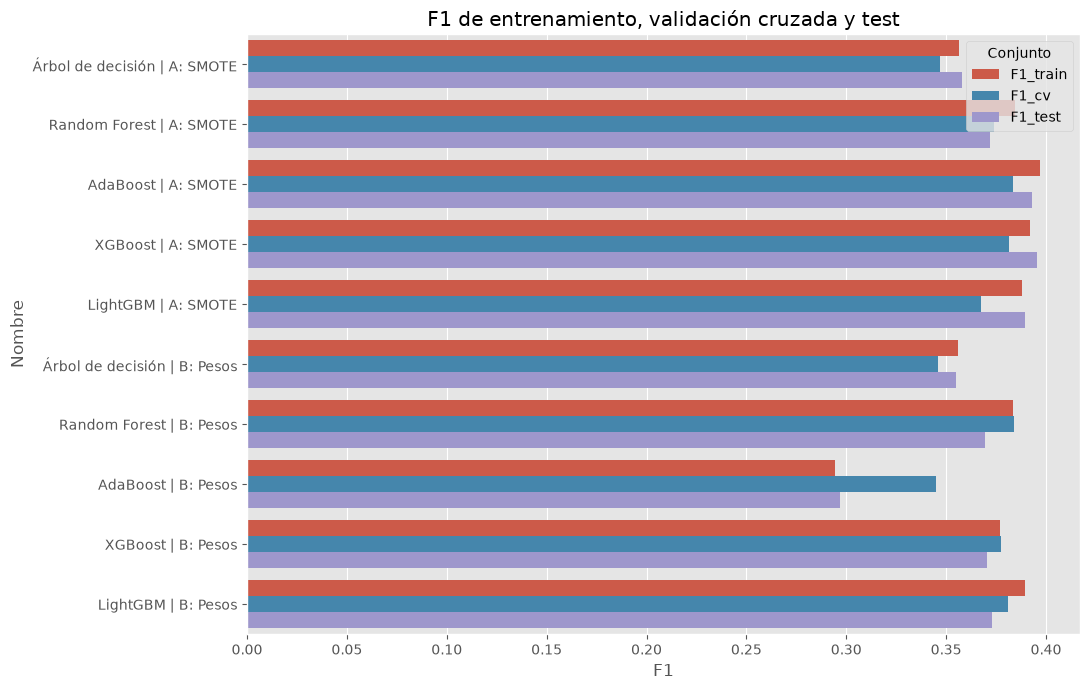

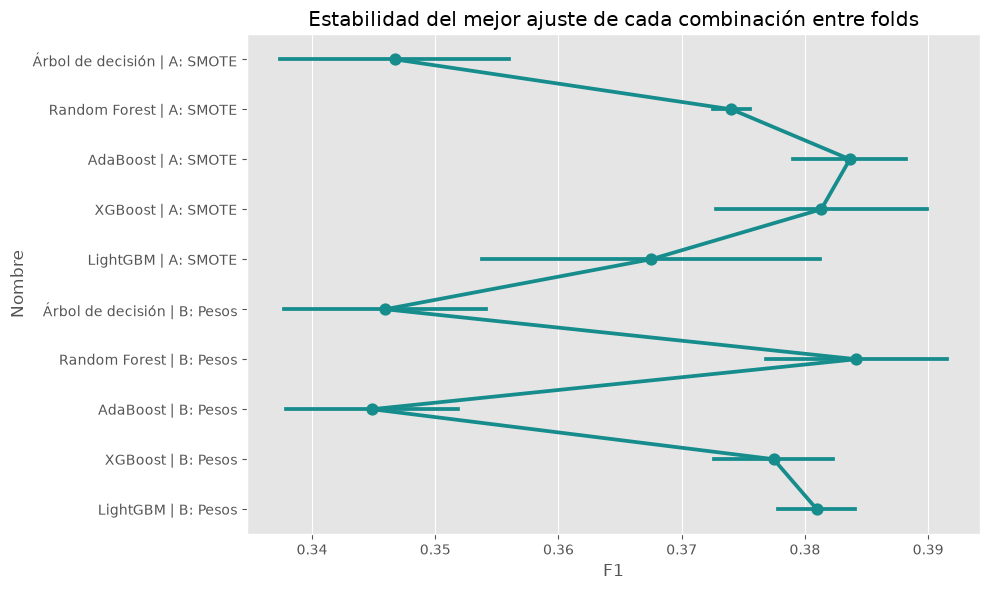

In [11]:
largo = comparacion.melt(
    id_vars="Nombre", value_vars=["F1_train", "F1_cv", "F1_test"],
    var_name="Conjunto", value_name="F1",
)
plt.figure(figsize=(11, 7))
sns.barplot(data=largo, y="Nombre", x="F1", hue="Conjunto")
plt.title("F1 de entrenamiento, validación cruzada y test")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.pointplot(data=tabla_cv, y="Nombre", x="F1", errorbar="sd", color="#168C8C")
plt.title("Estabilidad del mejor ajuste de cada combinación entre folds")
plt.tight_layout()
plt.show()

In [12]:
mejor = comparacion.loc[comparacion["F1_cv"].idxmax()]
print("Mejor combinación:", mejor["Nombre"])
print("F1-CV:", round(mejor["F1_cv"], 3), "±", round(mejor["Desv_cv"], 3))
print("F1-test:", round(mejor["F1_test"], 3))
print("Brecha train-test:", round(mejor["Brecha"], 3))
print("Hiperparámetros:", mejor["Hiperparametros"])

Mejor combinación: Random Forest | B: Pesos
F1-CV: 0.384 ± 0.006
F1-test: 0.369
Brecha train-test: 0.014
Hiperparámetros: {"n_estimators": 400, "max_features": "sqrt", "max_depth": 10}


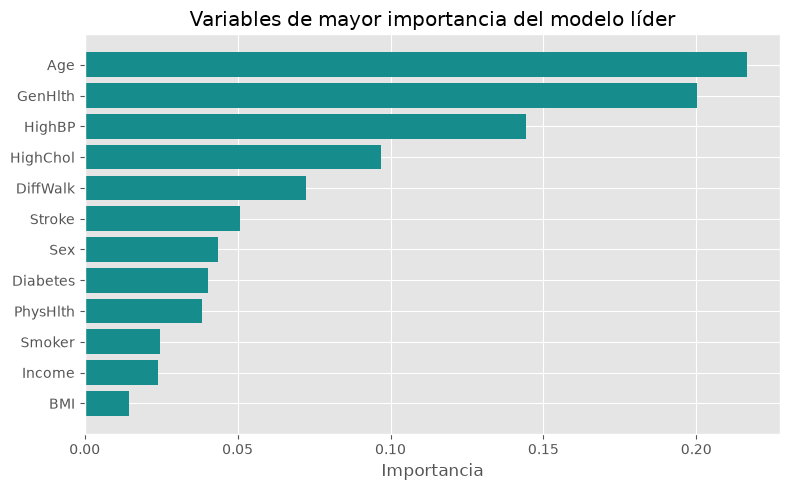

In [13]:
top = importancias.head(12).sort_values("Importancia")
plt.figure(figsize=(8, 5))
plt.barh(top["Variable"], top["Importancia"], color="#168C8C")
plt.title("Variables de mayor importancia del modelo líder")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

## 6. Matriz de costos en dinero

Para una probabilidad real $p=P(Y=1\mid X)$:

- predecir 0 cuesta $p\,C_{FN}$;
- predecir 1 cuesta $(1-p)\,C_{FP}$.

Se predice positivo cuando:

$$p \ge p^*=\frac{C_{FP}}{C_{FP}+C_{FN}}$$

Con CLP 100.000 y CLP 1.000.000, $p^*=0{,}091$. Como enseña el notebook del profesor, para usar esta regla el mejor algoritmo se reentrena **sin SMOTE ni pesos**, manteniendo sus hiperparámetros.

In [14]:
p_star = C_FP / (C_FP + C_FN)
print("Umbral teórico:", round(p_star, 3))
print("Umbral empírico por CV usando solo train:", resumen["umbral_empirico"])
display(estrategias.round(3))

Umbral teórico: 0.091
Umbral empírico por CV usando solo train: 0.09999999999999999


,Estrategia,VN,FP,FN,VP,Recall,Precision,Costo_total,Ahorro_vs_0_5
0,No hacer nada (todo 0),45957,0,4779,0,0.000,0.000,4779000000,-228300000
1,"Umbral 0,5",45830,127,4538,241,0.050,0.655,4550700000,0
2,Umbral teórico (0.091),31833,14124,716,4063,0.850,0.223,2128400000,2422300000
3,Umbral empírico (0.100),32909,13048,813,3966,0.830,0.233,2117800000,2432900000
4,"Modelo con pesos - Etapa B (Random Forest, 0,5)",33609,12348,898,3881,0.812,0.239,2132800000,2417900000


## 7. Umbral teórico, empírico y ahorro en test

El umbral empírico se seleccionó mediante `TunedThresholdClassifierCV` con train. La siguiente matriz usa test una sola vez para confirmar esa decisión.

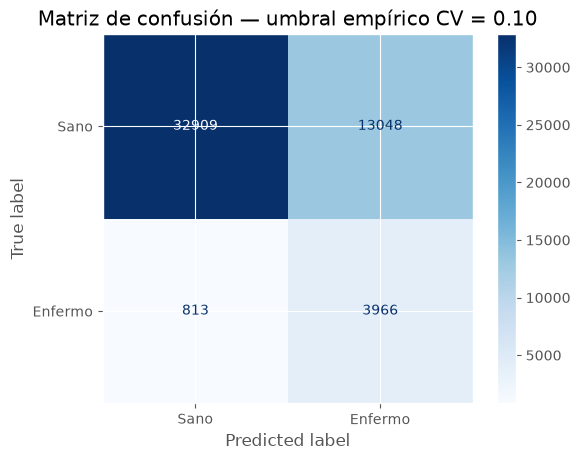

Recall: 0.83
Precisión: 0.233
Costo: CLP 2.117.800.000
Ahorro vs 0,5: CLP 2.432.900.000


In [15]:
y_dash = datos_dashboard["y_true"].to_numpy().astype(int)
p_dash = datos_dashboard["proba"].to_numpy()
t_emp = float(resumen["umbral_empirico"])
pred_emp = (p_dash >= t_emp).astype(int)
ConfusionMatrixDisplay.from_predictions(y_dash, pred_emp, display_labels=["Sano", "Enfermo"], cmap="Blues")
plt.title(f"Matriz de confusión — umbral empírico CV = {t_emp:.2f}")
plt.show()

fila_emp = estrategias[estrategias["Estrategia"].str.startswith("Umbral empírico")].iloc[0]
print("Recall:", round(fila_emp["Recall"], 3))
print("Precisión:", round(fila_emp["Precision"], 3))
print("Costo:", f"CLP {fila_emp['Costo_total']:,.0f}".replace(",", "."))
print("Ahorro vs 0,5:", f"CLP {fila_emp['Ahorro_vs_0_5']:,.0f}".replace(",", "."))

Como en `DT_Costo_Umbral_v2.ipynb`, se muestra además el barrido sobre test **solo como ilustración retrospectiva**. No se usa su mínimo para reportar rendimiento futuro.

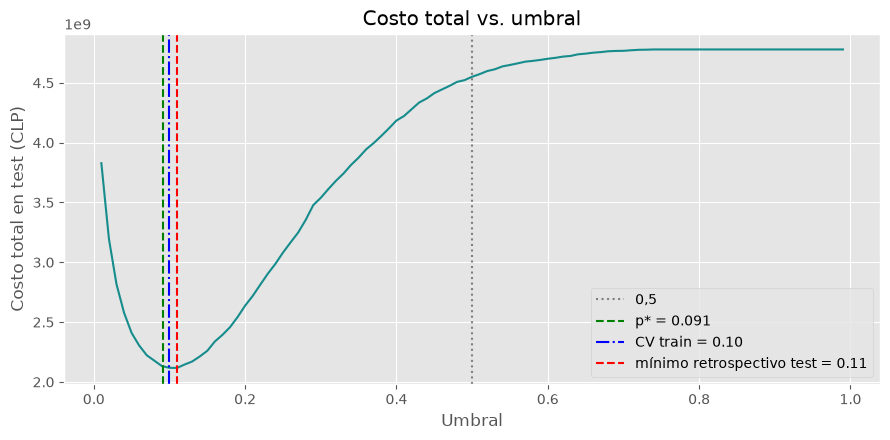

In [16]:
def costo_total(y_real, y_pred, c_fp=C_FP, c_fn=C_FN):
    _, fp, fn, _ = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return c_fp * fp + c_fn * fn

umbrales = np.linspace(0.01, 0.99, 99)
costos_test = np.array([costo_total(y_dash, (p_dash >= t).astype(int)) for t in umbrales])
t_min_test = float(umbrales[costos_test.argmin()])
plt.figure(figsize=(9, 4.5))
plt.plot(umbrales, costos_test, color="#168C8C")
plt.axvline(0.5, ls=":", color="gray", label="0,5")
plt.axvline(p_star, ls="--", color="green", label=f"p* = {p_star:.3f}")
plt.axvline(t_emp, ls="-.", color="blue", label=f"CV train = {t_emp:.2f}")
plt.axvline(t_min_test, ls="--", color="red", label=f"mínimo retrospectivo test = {t_min_test:.2f}")
plt.xlabel("Umbral")
plt.ylabel("Costo total en test (CLP)")
plt.title("Costo total vs. umbral")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Sensibilidad a la razón FN/FP

Los umbrales empíricos se obtienen con predicciones OOF de train. El test se usa después para medir el costo de cada escenario.

,Razon_FN_FP,p_teorico,Umbral_empirico,Costo_0_5,Costo_teorico,Costo_empirico,Ahorro_empirico_vs_0_5
0,2,0.333,0.31,920300000,846500000,843400000,76900000
1,5,0.167,0.16,2281700000,1534200000,1538100000,743600000
2,10,0.091,0.10,4550700000,2128400000,2117800000,2432900000
3,20,0.048,0.06,9088700000,2725000000,2697000000,6391700000
4,50,0.020,0.03,22702700000,3553700000,3408700000,19294000000


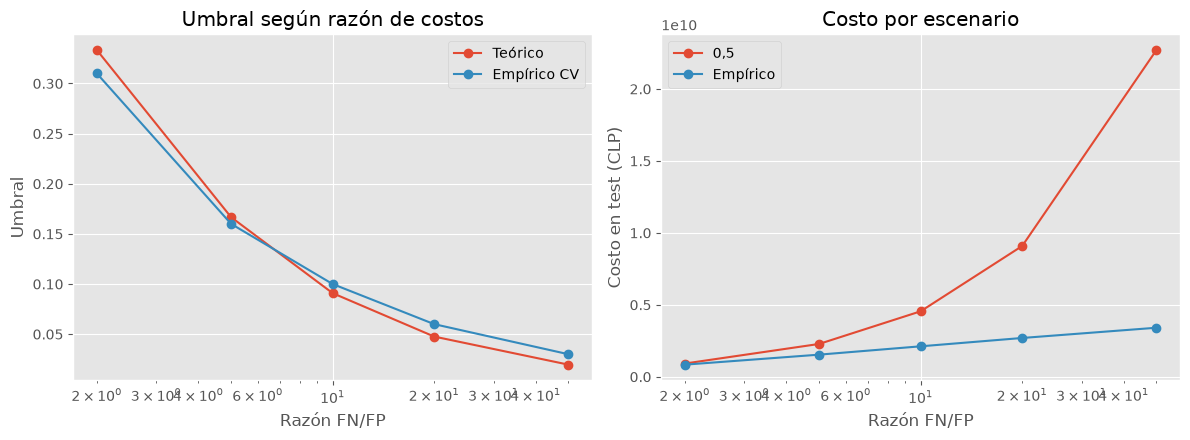

In [17]:
display(sensibilidad.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(sensibilidad["Razon_FN_FP"], sensibilidad["p_teorico"], marker="o", label="Teórico")
ax[0].plot(sensibilidad["Razon_FN_FP"], sensibilidad["Umbral_empirico"], marker="o", label="Empírico CV")
ax[0].set_xscale("log")
ax[0].set_xlabel("Razón FN/FP")
ax[0].set_ylabel("Umbral")
ax[0].set_title("Umbral según razón de costos")
ax[0].legend()
ax[1].plot(sensibilidad["Razon_FN_FP"], sensibilidad["Costo_0_5"], marker="o", label="0,5")
ax[1].plot(sensibilidad["Razon_FN_FP"], sensibilidad["Costo_empirico"], marker="o", label="Empírico")
ax[1].set_xscale("log")
ax[1].set_xlabel("Razón FN/FP")
ax[1].set_ylabel("Costo en test (CLP)")
ax[1].set_title("Costo por escenario")
ax[1].legend()
plt.tight_layout()
plt.show()

## 9. Dashboard y exportación

`datos_dashboard.csv` contiene únicamente `y_test`, probabilidades reales y probabilidades del mejor modelo ponderado. No contiene información personal. El dashboard se ejecuta con:

```bash
streamlit run app.py
```

In [18]:
print("Filas exportadas al dashboard:", len(datos_dashboard))
print("Columnas:", datos_dashboard.columns.tolist())
print("Aplicación:", ROOT / "app.py")

Filas exportadas al dashboard: 50736
Columnas: ['y_true', 'proba', 'proba_B']
Aplicación: /Users/namonaque/Documents/Código/UDD/Machine Learning - Supervisado/certamen 1/app.py


## 10. Sesgos, privacidad y limitaciones

- El dataset es una versión procesada de una encuesta autoinformada; puede contener sesgos de cobertura, recuerdo y respuesta.
- Edad, sexo, ingreso y acceso a salud pueden reflejar desigualdades estructurales. Antes de uso real debe compararse el desempeño por subgrupos.
- La importancia de variables no demuestra causalidad.
- Los costos son supuestos y por eso se presenta sensibilidad.
- Este trabajo es académico; no es un dispositivo clínico ni reemplaza evaluación profesional.
- La versión publicada no incluye identificadores personales ni el CSV original.

In [19]:
# Comprobación exploratoria por sexo sobre el mismo test; no constituye auditoría clínica.
# La partición se reproduce con la misma semilla, por lo que el orden coincide con datos_dashboard.csv.
assert np.array_equal(y_test.to_numpy(), y_dash)
filas_grupo = []
for sexo, idx in X_test.groupby("Sex").groups.items():
    posiciones = X_test.index.get_indexer(idx)
    yt = y_dash[posiciones]
    yp = pred_emp[posiciones]
    filas_grupo.append({
        "Sex": int(sexo),
        "N": len(posiciones),
        "Positivos": int(yt.sum()),
        "Recall": recall_score(yt, yp, zero_division=0),
        "Precisión": precision_score(yt, yp, zero_division=0),
    })
display(pd.DataFrame(filas_grupo).round(3))

,Sex,N,Positivos,Recall,Precisión
0,0,28294,2013,0.801,0.203
1,1,22442,2766,0.851,0.259


## 11. Conclusiones para la gerencia

1. El modelo líder se selecciona por F1-CV, no por test.
2. SMOTE/pesos resuelven el desbalance durante la comparación; no se combinan con un umbral reducido en la Parte 2.
3. Para costos, el mejor algoritmo se reentrena con la proporción real.
4. Un FN cuesta diez veces un FP en el escenario base, por lo que 0,5 no es la decisión económica adecuada.
5. El umbral empírico se aprende en train y se confirma una sola vez en test.
6. La recomendación depende de costos supuestos; la sensibilidad muestra cómo cambia cuando la razón FN/FP varía.

## Declaración de uso de inteligencia artificial

Se utilizó asistencia de IA para revisar estructura, depurar código, documentar decisiones y preparar el dashboard. El grupo adaptó el código al BRFSS 2015, verificó los resultados y debe ser capaz de explicar cada pipeline, métrica, costo y umbral durante la exposición.